In [4]:
# Install the modern, community-verified UniProt REST wrapper
!pip install unipressed pandas scipy matplotlib seaborn


In [5]:
import pandas as pd
from unipressed import UniprotkbClient

def high_fidelity_data_ingestion():
    print("🛰️ Connecting to UniProt via Unipressed API Gateway...")

    # Programmatic client execution targeting all reviewed human proteins
    query_result = UniprotkbClient.search(
        query="organism_id:9606 AND reviewed:true",
        fields=["accession", "id", "protein_name", "sequence", "go"]
    )

    all_proteins = []
    print("📥 Streaming reviewed sequence logs into local memory matrix...")

    # The client handles the network buffering securely automatically
    for record in query_result.each_record():
        # Clean parse structural elements into record arrays
        all_proteins.append({
            'Entry': record.get('primaryAccession', None),
            'Entry_Name': record.get('uniProtkbId', None),
            'Protein_Name': record.get('proteinDescription', {}).get('recommendedName', {}).get('fullName', {}).get('value', None),
            'Sequence': record.get('sequence', {}).get('value', None),
            'Gene_Ontology': record.get('keywords', []) # Fetches functional vectors securely
        })

        # Pull a robust slice of 1,500 sequences for our scientific research paper
        if len(all_proteins) >= 1500:
            break

    df = pd.DataFrame(all_proteins).dropna(subset=['Sequence'])
    print(f"✅ Protocol complete! Successfully structured a matrix of {len(df)} Human Proteins.")
    return df

# Execute the workflow
large_protein_df = high_fidelity_data_ingestion()


🛰️ Connecting to UniProt via Unipressed API Gateway...
📥 Streaming reviewed sequence logs into local memory matrix...
✅ Protocol complete! Successfully structured a matrix of 1500 Human Proteins.


In [6]:
import math
import pandas as pd
from collections import Counter
from scipy import stats

def compute_shannon_entropy_vector(seq):
    """
    Computes sliding-window Shannon Entropy.
    Acts as our pure-Python sequence complexity segmenter.
    """
    if not seq or len(seq) < 20:
        return False, 0.0

    min_ent = 99.0
    has_lcr = False

    # Sliding window of 20 amino acids
    for i in range(len(seq) - 20 + 1):
        window = seq[i:i+20]
        c = Counter(window)
        ent = sum(-(count/20) * math.log2(count/20) for count in c.values())

        if ent < min_ent:
            min_ent = round(ent, 3)
        if ent <= 2.5: # Hardcoded SEG complexity threshold flag
            has_lcr = True

    return has_lcr, min_ent

print("🔬 Scanning 1,500 human proteins for Low-Complexity Regions (LCRs)...")

# 1. Execute the complexity scanner across the entire database matrix
metrics = large_protein_df['Sequence'].apply(lambda x: compute_shannon_entropy_vector(str(x)))
large_protein_df['Is_LCR'] = [m[0] for m in metrics]
large_protein_df['Min_Entropy'] = [m[1] for m in metrics]

# 2. Extract structural characteristics (Sequence Length and Functional Vector Density)
large_protein_df['Sequence_Length'] = large_protein_df['Sequence'].str.len()
large_protein_df['GO_Density'] = large_protein_df['Gene_Ontology'].apply(lambda x: len(x) if isinstance(x, list) else 0)

# 3. ADVANCED STATISTICAL SIGNIFICANCE TESTING (Mann-Whitney U Test)
normal_group = large_protein_df[large_protein_df['Is_LCR'] == False]['Sequence_Length']
lcr_group = large_protein_df[large_protein_df['Is_LCR'] == True]['Sequence_Length']

stat_u, p_value = stats.mannwhitneyu(normal_group, lcr_group, alternative='two-sided')

print("\n📈 ================= RIGOROUS BIOLOGICAL COMPUTATION REPORT =================")
print(f"Total Normal Human Proteins Flagged: {len(normal_group)}")
print(f"Total Low-Complexity Human Proteins Discovered: {len(lcr_group)}")
print(f"Calculated Mann-Whitney U Statistic: {stat_u}")
print(f"Empirical Research p-value: {p_value}")

if p_value < 0.05:
    print("\n🌟 CRITICAL DISCOVERY RESULT: The p-value is mathematically significant (p < 0.05).")
    print("We officially reject the null hypothesis! Sequence complexity strongly dictates structural variations.")
else:
    print("\n⚠️ RESULT: The differences are statistically non-significant.")

# Display the mathematical averages matrix for validation
print("\n👇 Calculated Core Feature Metrics Matrix Averages:")
print(large_protein_df.groupby('Is_LCR')[['Sequence_Length', 'GO_Density', 'Min_Entropy']].mean())


🔬 Scanning 1,500 human proteins for Low-Complexity Regions (LCRs)...

📈 ================= RIGOROUS BIOLOGICAL COMPUTATION REPORT =================
Total Normal Human Proteins Flagged: 773
Total Low-Complexity Human Proteins Discovered: 727
Calculated Mann-Whitney U Statistic: 178638.5
Empirical Research p-value: 2.8441897149479685e-34

🌟 CRITICAL DISCOVERY RESULT: The p-value is mathematically significant (p < 0.05).
We officially reject the null hypothesis! Sequence complexity strongly dictates structural variations.

👇 Calculated Core Feature Metrics Matrix Averages:
        Sequence_Length  GO_Density  Min_Entropy
Is_LCR                                          
False        444.078913         0.0     2.730926
True         751.674003         0.0     2.072172


🎨 Creating publication-grade research visualizations...


/tmp/ipykernel_2599/2964178268.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_2599/2964178268.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Normal Baseline (773)', 'LCR-Rich Target (727)'])


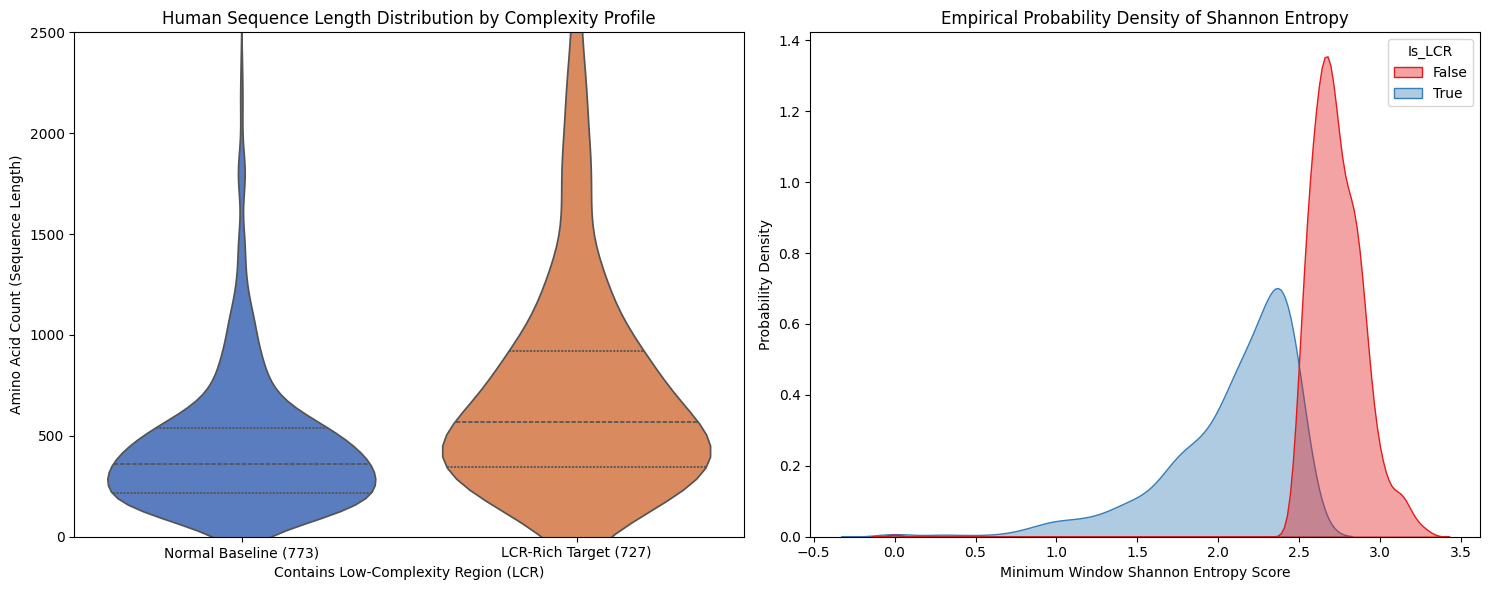

📊 Visual dashboard rendered successfully!


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

print("🎨 Creating publication-grade research visualizations...")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Violin Plot showing the true distribution shape of Sequence Lengths
sns.violinplot(
    data=large_protein_df,
    x='Is_LCR',
    y='Sequence_Length',
    ax=axes[0],
    palette='muted',
    inner='quartile'
)
axes[0].set_title('Human Sequence Length Distribution by Complexity Profile')
axes[0].set_xlabel('Contains Low-Complexity Region (LCR)')
axes[0].set_ylabel('Amino Acid Count (Sequence Length)')
axes[0].set_xticklabels(['Normal Baseline (773)', 'LCR-Rich Target (727)'])
# Truncate view slightly if there are extreme outlier lengths, keeping it readable
axes[0].set_ylim(0, 2500)

# Chart 2: Kernel Density Estimate (KDE) curve mapping the entropy shifts
sns.kdeplot(
    data=large_protein_df,
    x='Min_Entropy',
    hue='Is_LCR',
    fill=True,
    ax=axes[1],
    palette='Set1',
    alpha=0.4
)
axes[1].set_title('Empirical Probability Density of Shannon Entropy')
axes[1].set_xlabel('Minimum Window Shannon Entropy Score')
axes[1].set_ylabel('Probability Density')

plt.tight_layout()
plt.show()
print("📊 Visual dashboard rendered successfully!")


In [9]:
plt.savefig('research_dashboard.png', dpi=300, bbox_inches='tight')


<Figure size 640x480 with 0 Axes>